# Système de recommandation hybride d'offres d'emploi
**Dataset : JTH – Job Tracking History** (Romero, Millet & Behar, RecSys'26, licence CC BY-NC 4.0, usage recherche non commercial).

Objectif : recommander à un candidat les offres d'emploi actives les plus pertinentes, en combinant trois moteurs
(**contenu**, **collaboratif**, **connaissances**) selon les **7 stratégies d'hybridation** de Burke, puis comparer
ces hybrides à chaque moteur seul et à une baseline de **popularité**, y compris en situation de **cold-start**.

Le code réutilisable est dans le paquet `jobrec/` (commenté) ; ce notebook l'orchestre :
1. Chargement et nettoyage · 2. Analyse exploratoire · 3. Découpage temporel · 4. Moteurs de base ·
5. Réglage des hybrides (validation) · 6. Évaluation sur le test · 7. Cold-start · 8. Interprétabilité et explications.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)

from jobrec.data import load_jth, temporal_split, History, JobPool, estimate_pool_window, build_queries, STAGE_COLS
from jobrec.features import Profiles
from jobrec.engines import Context
from jobrec import hybrids as H
from jobrec.evaluation import make_pool_fn, precompute, quick_ndcg, evaluate, summarize
from jobrec.explain import explain

DATA_DIR = os.environ.get("JTH_DIR", "data")   # dossier contenant candidates.csv, jobs.csv, history.csv
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
SEED = 42
MAX_VAL_QUERIES = 1500      # requêtes de validation utilisées pour le réglage
MAX_TEST_QUERIES = None     # None = toutes les requêtes de test
K = 10

## 1. Chargement et nettoyage

Choix de modélisation :
* **Interaction** = une ligne de `history.csv` (un candidat positionné sur une offre) → retour **implicite positif**.
* **Date** de l'interaction = première étape renseignée de l'entonnoir (comme le découpage officiel JTH).
* Nettoyage : lignes sans date, identifiants inconnus, doublons candidat–offre (on garde la plus ancienne).
* Les champs « liste » mélangent `a;b`, `['a','b']` et `a, b` → parseur unique, minuscules, suppression de la sentinelle `_rare_skill_`.

In [2]:
t0 = time.time()
D = load_jth(DATA_DIR)
cand, jobs, inter = D.candidates, D.jobs, D.interactions
print(f"Chargé en {time.time()-t0:.1f}s")
print("Journal de nettoyage :", D.cleaning_log)

Chargé en 0.8s
Journal de nettoyage : {'history_rows_raw': 42288, 'dropped_no_date': 0, 'dropped_unknown_ids': 0, 'dropped_duplicates': 980, 'history_rows_clean': 41308}


## 2. Analyse exploratoire

In [3]:
n_u, n_i, n_r = cand.shape[0], jobs.shape[0], len(inter)
n_u_act, n_i_act = inter.u.nunique(), inter.j.nunique()
density = n_r / (n_u_act * n_i_act)
stats = pd.Series({
    "Candidats (fichier)": n_u, "Offres (fichier)": n_i, "Interactions": n_r,
    "Candidats avec ≥1 interaction": n_u_act, "Offres avec ≥1 interaction": n_i_act,
    "Interactions / candidat actif": n_r / n_u_act, "Interactions / offre active": n_r / n_i_act,
    "Densité de la matrice (%)": 100 * density, "Sparsité (%)": 100 * (1 - density),
    "Période": f"{pd.to_datetime(inter.t.min(), unit='D').date()} → {pd.to_datetime(inter.t.max(), unit='D').date()}",
})
stats.to_frame("valeur")

,valeur
Candidats (fichier),37554
Offres (fichier),6011
Interactions,41308
Candidats avec ≥1 interaction,26101
Offres avec ≥1 interaction,4116
Interactions / candidat actif,1.5826
Interactions / offre active,10.036
Densité de la matrice (%),0.0385
Sparsité (%),99.9615
Période,2018-03-09 → 2025-04-21


Candidats avec une seule interaction : 69.4 %
Répartition interactions/candidat : {'mean': 1.58, '50%': 1.0, 'max': 16.0}
Répartition interactions/offre    : {'mean': 10.04, '50%': 5.0, 'max': 156.0}
Gini de la popularité des offres = 0.609 ; les 10 % d'offres les plus populaires = 45.1 % des interactions


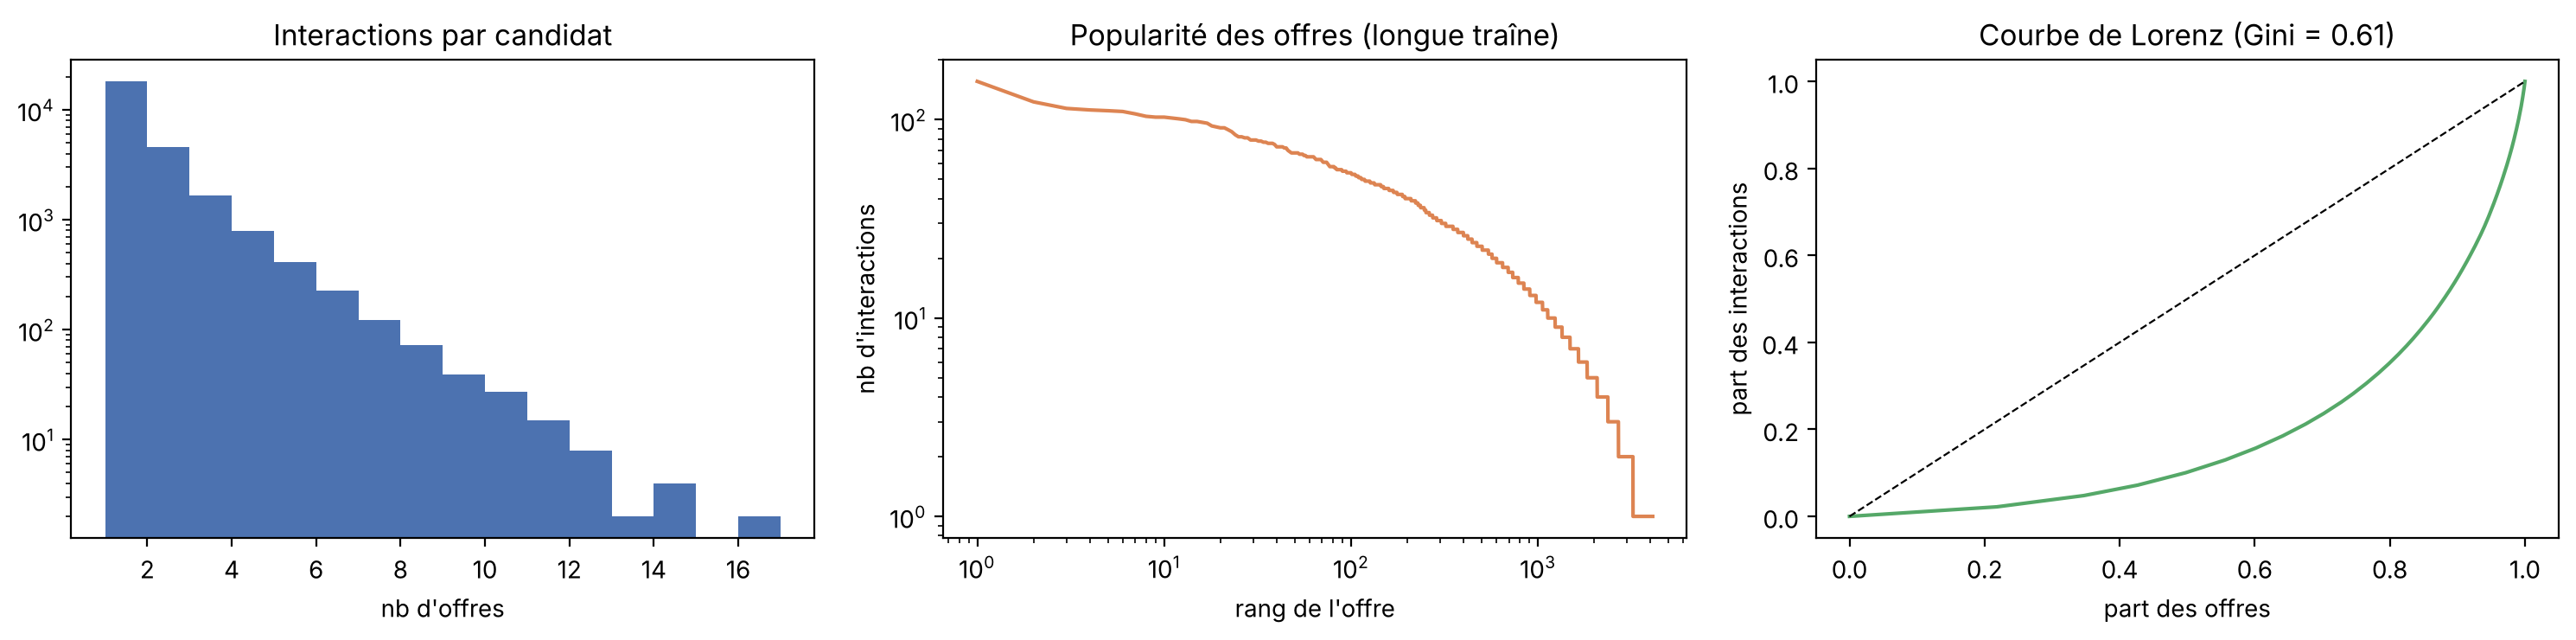

In [4]:
per_u = inter.groupby("u").size(); per_i = inter.groupby("j").size()
print("Candidats avec une seule interaction : %.1f %%" % (100 * (per_u == 1).mean()))
print("Répartition interactions/candidat :", per_u.describe()[["mean", "50%", "max"]].round(2).to_dict())
print("Répartition interactions/offre    :", per_i.describe()[["mean", "50%", "max"]].round(2).to_dict())

# Concentration de la popularité (courbe de Lorenz + indice de Gini)
x = np.sort(per_i.values); lorenz = np.cumsum(x) / x.sum()
gini = 1 - 2 * np.trapezoid(lorenz, dx=1 / len(x))
top10 = np.sort(per_i.values)[::-1][: max(1, len(per_i) // 10)].sum() / per_i.sum()
print(f"Gini de la popularité des offres = {gini:.3f} ; les 10 % d'offres les plus populaires = {100*top10:.1f} % des interactions")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(per_u, bins=range(1, per_u.max() + 2), log=True, color="#4C72B0"); ax[0].set_title("Interactions par candidat"); ax[0].set_xlabel("nb d'offres")
ax[1].plot(np.arange(1, len(per_i) + 1), np.sort(per_i.values)[::-1], color="#DD8452"); ax[1].set_yscale("log"); ax[1].set_xscale("log")
ax[1].set_title("Popularité des offres (longue traîne)"); ax[1].set_xlabel("rang de l'offre"); ax[1].set_ylabel("nb d'interactions")
ax[2].plot(np.linspace(0, 1, len(x)), lorenz, color="#55A868"); ax[2].plot([0, 1], [0, 1], "k--", lw=.8)
ax[2].set_title(f"Courbe de Lorenz (Gini = {gini:.2f})"); ax[2].set_xlabel("part des offres"); ax[2].set_ylabel("part des interactions")
plt.tight_layout(); plt.savefig(f"{FIG}/popularite.png", dpi=150); plt.show()

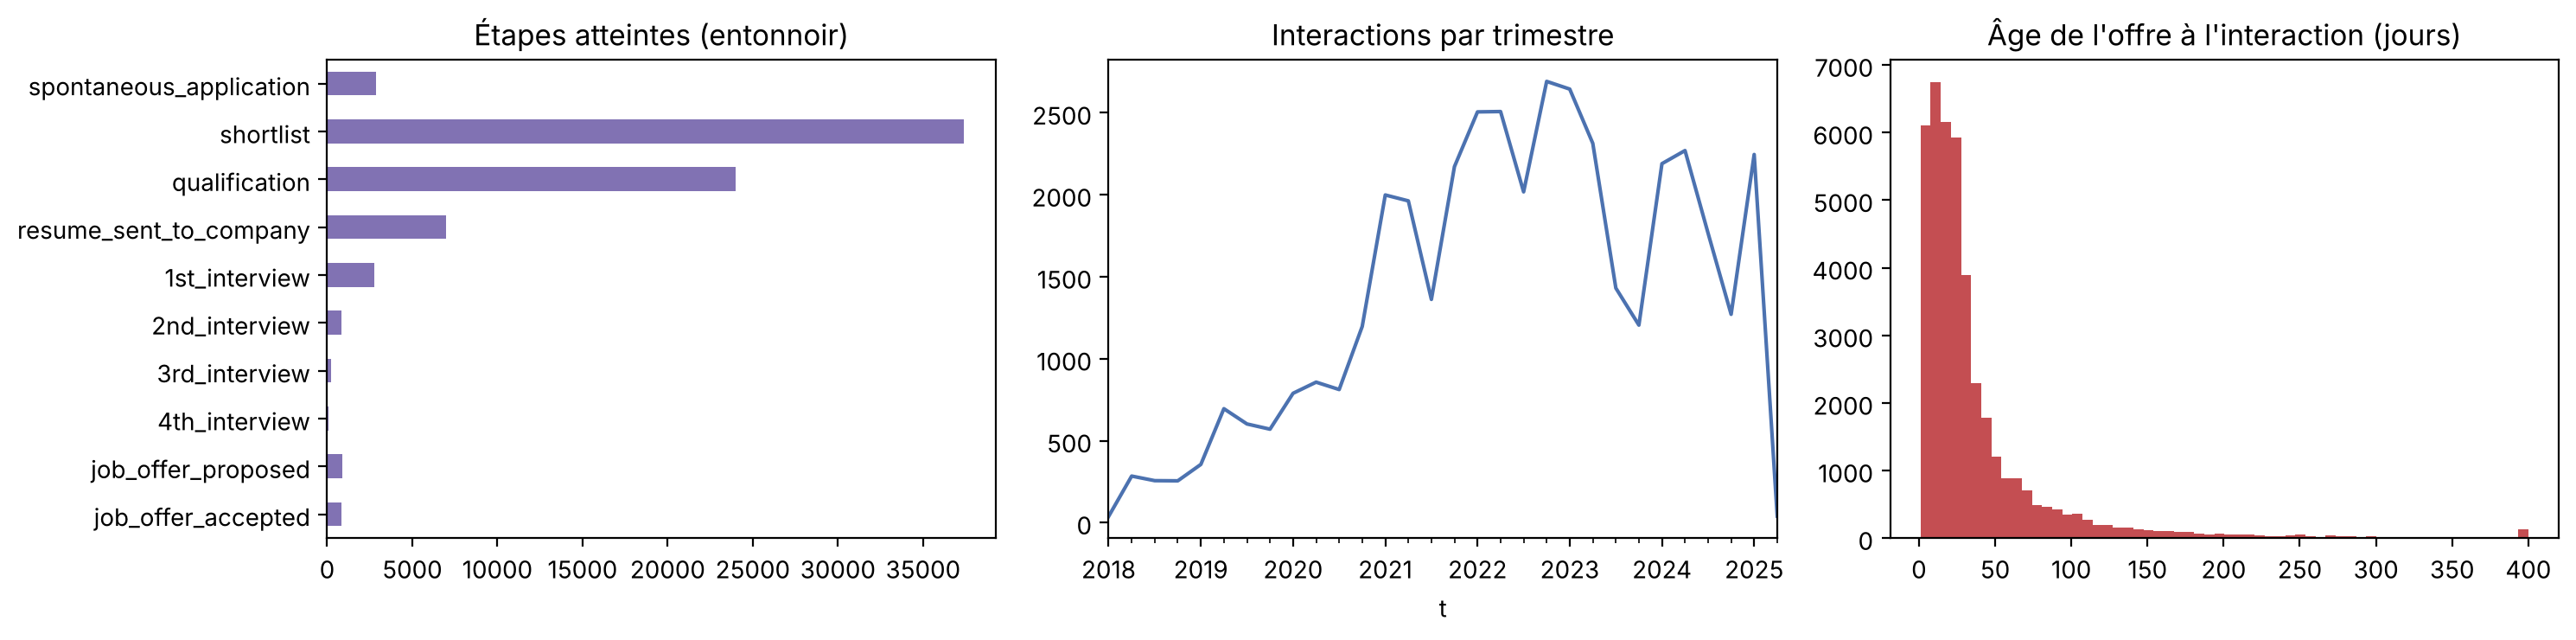

Quantiles de l'âge des offres à l'interaction : [ 22.  40.  81. 124.]


In [5]:
# Entonnoir de recrutement : combien d'interactions atteignent chaque étape ?
raw = D.raw_history
funnel = pd.Series({c.replace("_date", ""): raw[c].notna().sum() for c in STAGE_COLS if c in raw})
months = pd.to_datetime(inter.t, unit="D").dt.to_period("Q").value_counts().sort_index()

# Âge de l'offre au moment de l'interaction → durée de vie d'une offre
age = inter.t.values - jobs.create_day.values[inter.j.values]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
funnel.plot.barh(ax=ax[0], color="#8172B3"); ax[0].invert_yaxis(); ax[0].set_title("Étapes atteintes (entonnoir)")
months.plot(ax=ax[1], color="#4C72B0"); ax[1].set_title("Interactions par trimestre")
ax[2].hist(np.clip(age, -30, 400), bins=60, color="#C44E52"); ax[2].set_title("Âge de l'offre à l'interaction (jours)")
plt.tight_layout(); plt.savefig(f"{FIG}/entonnoir_temps.png", dpi=150); plt.show()
print("Quantiles de l'âge des offres à l'interaction :", np.percentile(age[age >= 0], [50, 75, 90, 95]).round())

In [6]:
# Valeurs manquantes des principaux attributs (justifie la gestion de l'« inconnu » dans le moteur à connaissances)
cols = ["skills", "expertise_area", "job_category", "years_experience", "contract_type", "zipcode",
        "llm_highest_diploma", "llm_required_lowest_diploma", "llm_seniority_level", "llm_hard_skills"]
miss = pd.DataFrame({"candidats (%)": [100 * cand[c].isna().mean() if c in cand else np.nan for c in cols],
                     "offres (%)": [100 * jobs[c].isna().mean() if c in jobs else np.nan for c in cols]}, index=cols).round(1)
miss

,candidats (%),offres (%)
skills,11.4,2.2
expertise_area,8.0,30.6
job_category,26.8,78.6
years_experience,83.5,88.9
contract_type,14.9,0.0
zipcode,41.6,2.1
llm_highest_diploma,0.0,NaN
llm_required_lowest_diploma,NaN,0.0
llm_seniority_level,0.0,0.0
llm_hard_skills,12.1,0.3


## 3. Découpage temporel train / validation / test

* **Test** = les 20 % d'interactions les plus récentes (découpage chronologique : pas de fuite du futur).
* **Validation** = les 10 % les plus récents de l'entraînement, pour régler les hybrides (poids, seuils).
* À une date *t*, un moteur ne voit **que les interactions antérieures à t** (comme un système en production) ;
  les paramètres appris (IDF du TF-IDF, régression logistique, poids) sont figés à la fin de l'entraînement.
* **Offres candidates** à la date *t* : offres créées depuis moins de *W* jours, avec *W* = quantile 95 % de
  l'âge des offres au moment des candidatures (mesuré sur l'entraînement). On exclut les offres déjà vues par le candidat.

In [7]:
train, test = temporal_split(inter, 0.8)
fit, val = temporal_split(train, 0.9)
W = estimate_pool_window(train, jobs.create_day.values, q=0.95)
train_end = int(train.t.max())
print(f"train={len(train)}  (dont validation={len(val)})  test={len(test)}  |  fenêtre d'activité W={W} jours")
print("Fin de l'entraînement :", pd.to_datetime(train_end, unit="D").date())

hist = History(inter, n_u, n_i)              # interrogé uniquement « avant t »
pool = JobPool(jobs.create_day.values.astype(int), W)
prof = Profiles(cand, jobs, fit_cutoff_day=train_end)
ctx = Context(prof, hist, pop_window=30, profile_beta=0.5, knn_k=50)
pool_fn = make_pool_fn(ctx, pool)

q_train, q_val, q_test = build_queries(train), build_queries(val), build_queries(test)
def describe(q, name):
    cold_u = np.mean([len(hist.items_of(u, t)) == 0 for u, t in zip(q.u, q.t)])
    cold_i = np.mean([all(len(hist.users_of(j, t)) == 0 for j in js) for js, t in zip(q.true_items, q.t)])
    in_pool = np.mean([np.isin(js, pool.at(t)).any() for js, t in zip(q.true_items, q.t)])
    sizes = [len(pool.at(t)) for t in q.t[:: max(1, len(q) // 300)]]
    return {"requêtes": len(q), "candidats nouveaux (%)": 100 * cold_u, "offres vraies sans historique (%)": 100 * cold_i,
            "offre vraie dans l'espace actif (%)": 100 * in_pool, "taille moyenne de l'espace": np.mean(sizes)}
pd.DataFrame({"validation": describe(q_val, "val"), "test": describe(q_test, "test")}).round(1)

train=33046  (dont validation=3305)  test=8262  |  fenêtre d'activité W=101 jours
Fin de l'entraînement : 2024-03-09


,validation,test
requêtes,3295.0,8216.0
candidats nouveaux (%),67.2,66.2
offres vraies sans historique (%),11.5,5.7
offre vraie dans l'espace actif (%),94.7,84.9
taille moyenne de l'espace,194.5,140.6


Le cold-start n'est pas une expérience artificielle ici : la grande majorité des requêtes de test concernent un candidat
**sans aucun historique** et/ou une offre **jamais vue**. C'est la difficulté centrale du recrutement (marché biface, entités éphémères).

## 4. Les moteurs de base

| Moteur | Idée | Fonctionne pour un nouveau candidat ? | … une nouvelle offre ? |
|---|---|---|---|
| **Popularité** (baseline) | offres ayant reçu le plus de candidatures sur les 30 derniers jours | oui | non |
| **Contenu** (TF-IDF) | cosinus entre profil (compétences, domaines, soft skills) du candidat et de l'offre ; profil enrichi des offres passées | oui | oui |
| **Collaboratif** (item-kNN) | offres co-positionnées avec celles du candidat (cosinus binaire) | **non** | non |
| **Connaissances** | part des contraintes satisfaites : diplôme, expérience, séniorité, lieu/télétravail, contrat, langues, management | oui | oui |

In [8]:
# Exemple sur une requête de validation
u, t, true = int(q_val.u.iloc[0]), int(q_val.t.iloc[0]), q_val.true_items.iloc[0]
p = pool_fn(u, t); comp = H.components(ctx, u, t, p)
print(f"candidat {u}, {len(p)} offres actives, historique = {comp['n_past']} offre(s)")
for k in ["pop", "cb", "cf", "kb", "meta"]:
    order = np.argsort(-comp[k]); r = np.flatnonzero(np.isin(p[order], true))
    print(f"  {k:5s} rang de l'offre vraie : {r[0]+1 if len(r) else '—'}")

candidat 23234, 206 offres actives, historique = 1 offre(s)
  pop   rang de l'offre vraie : 37
  cb    rang de l'offre vraie : 3
  cf    rang de l'offre vraie : 1
  kb    rang de l'offre vraie : 49
  meta  rang de l'offre vraie : 1


## 5. Réglage des hybrides sur la validation

In [9]:
qv = q_val.sample(min(MAX_VAL_QUERIES, len(q_val)), random_state=SEED).sort_values("t")
t0 = time.time(); cached_val = precompute(ctx, qv, pool_fn); print(f"{len(cached_val)} requêtes précalculées en {time.time()-t0:.0f}s")

# Base : NDCG@10 de chaque moteur seul
base_val = {k: quick_ndcg(cached_val, lambda c, k=k: c[k]) for k in H.BASE_KEYS}
print("NDCG@10 validation par moteur :", {k: round(v, 4) for k, v in base_val.items()})

1500 requêtes précalculées en 6s


NDCG@10 validation par moteur : {'pop': 0.1624, 'cb': 0.3772, 'cf': 0.1252, 'kb': 0.0708, 'meta': 0.4272}


In [10]:
# H1 — Pondéré : recherche exhaustive des poids (pas de 0.1, somme = 1) qui maximisent NDCG@10
t0 = time.time()
grid = [(quick_ndcg(cached_val, lambda c, w=w: H.weighted(c, w)), w) for w in H.weight_grid(("pop", "cb", "cf", "kb"), 0.1)]
grid.sort(key=lambda x: -x[0]); W_BEST = grid[0][1]
print(f"{len(grid)} combinaisons en {time.time()-t0:.0f}s — meilleurs poids : {W_BEST}  NDCG@10={grid[0][0]:.4f}")
pd.DataFrame([dict(ndcg=s, **w) for s, w in grid[:5]])

286 combinaisons en 43s — meilleurs poids : {'pop': 0.2, 'cb': 0.30000000000000004, 'cf': 0.2, 'kb': 0.30000000000000004}  NDCG@10=0.4989


,ndcg,pop,cb,cf,kb
0,0.4989,0.2,0.3,0.2,0.3
1,0.4961,0.1,0.2,0.4,0.3
2,0.4958,0.1,0.2,0.5,0.2
3,0.4954,0.2,0.3,0.3,0.2
4,0.4940,0.1,0.2,0.6,0.1


In [11]:
# H2 — Commutation (règle classique) : collaboratif si le candidat a au moins n_min offres
# dans son historique ET que le CF produit un signal, sinon contenu. On règle n_min.
# (Le méta-niveau H7, déjà un hybride, est volontairement exclu des moteurs commutables.)
cold_c = [c for c in cached_val if c[4]["n_past"] == 0]; warm_c = [c for c in cached_val if c[4]["n_past"] > 0]
print("Validation, candidats connus — NDCG@10 CF = %.4f, contenu = %.4f" % (
    quick_ndcg(warm_c, lambda c: c["cf"]), quick_ndcg(warm_c, lambda c: c["cb"])))
SW = max(({"n_min": n, "warm": "cf", "cold": "cb"} for n in (1, 2, 3, 4)),
         key=lambda cfg: quick_ndcg(cached_val, lambda c: H.switching(c, cfg)))
print("Commutation retenue :", SW, f"({len(warm_c)} requêtes 'connues' / {len(cold_c)} 'nouvelles' en validation)")

# H4 — Cascade : seuil d'éligibilité ; second étage = pondération sans le moteur à connaissances
second = {k: v for k, v in W_BEST.items() if k != "kb"} or {"cb": 1.0}
if sum(second.values()) == 0: second = {"cb": 1.0}
TAU = max((0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8), key=lambda tau: quick_ndcg(cached_val, lambda c: H.cascade(c, tau, second)))
elim = np.mean([np.mean(c[4]["kb"] < TAU) for c in cached_val])
print("Cascade : seuil τ =", TAU, "| second étage :", second, f"| offres éliminées en moyenne : {100*elim:.1f} %")

Validation, candidats connus — NDCG@10 CF = 0.3181, contenu = 0.3163


Commutation retenue : {'n_min': 1, 'warm': 'cf', 'cold': 'cb'} (508 requêtes 'connues' / 992 'nouvelles' en validation)


Cascade : seuil τ = 0.3 | second étage : {'pop': 0.2, 'cb': 0.30000000000000004, 'cf': 0.2} | offres éliminées en moyenne : 2.1 %


In [12]:
# H5 / H6 — régression logistique entraînée sur des requêtes de l'entraînement (échantillonnage négatif 1:20)
t0 = time.time()
Xr, Xa, y = H.build_ltr_dataset(ctx, q_train, pool_fn, n_neg=20, seed=SEED, max_queries=6000)
ltr_raw = H.LTRHybrid(augmented=False).fit(Xr, y)
ltr_aug = H.LTRHybrid(augmented=True).fit(Xa, y)
print(f"{len(y)} couples ({y.sum()} positifs) en {time.time()-t0:.0f}s")
# Remarque : les requêtes de validation font partie de l'entraînement du modèle ; ce chiffre est donc optimiste.
for name, m, aug in [("comb. features", ltr_raw, False), ("augm. features", ltr_aug, True)]:
    v = np.mean([__import__("jobrec.evaluation", fromlist=["x"]).ndcg_for(
        np.argsort(-m.score_from_features(H.pair_features(ctx, u, t, p, c, augmented=aug))), p, tr, 10)
        for (u, t, p, tr, c) in cached_val])
    print(f"NDCG@10 validation ({name}) : {v:.4f}")

120279 couples (5759 positifs) en 36s


NDCG@10 validation (comb. features) : 0.4785


NDCG@10 validation (augm. features) : 0.6124


## 6. Évaluation sur le test

In [13]:
def ltr_fn(model, aug):
    return lambda c, u, t, p: model.score_from_features(H.pair_features(ctx, u, t, p, c, augmented=aug))

METHODS = {
    "Popularité (baseline)":       lambda c, u, t, p: c["pop"],
    "Contenu":                     lambda c, u, t, p: c["cb"],
    "Collaboratif":                lambda c, u, t, p: c["cf"],
    "Connaissances":               lambda c, u, t, p: c["kb"],
    "H1 Pondéré":                  lambda c, u, t, p: H.weighted(c, W_BEST),
    "H2 Commutation":              lambda c, u, t, p: H.switching(c, SW),
    "H3 Mixte":                    lambda c, u, t, p: H.mixed(c),
    "H4 Cascade":                  lambda c, u, t, p: H.cascade(c, TAU, second),
    "H5 Combinaison de features":  ltr_fn(ltr_raw, False),
    "H6 Augmentation de features": ltr_fn(ltr_aug, True),
    "H7 Méta-niveau":              lambda c, u, t, p: c["meta"],
}
qt = q_test if MAX_TEST_QUERIES is None else q_test.sample(MAX_TEST_QUERIES, random_state=SEED).sort_values("t")
t0 = time.time(); cached_test = precompute(ctx, qt, pool_fn); print(f"{len(cached_test)} requêtes de test précalculées en {time.time()-t0:.0f}s")
t0 = time.time(); res = evaluate(cached_test, METHODS, ctx, ks=(5, K)); print(f"évaluation en {time.time()-t0:.0f}s")
summary = summarize(res, cached_test, ks=(5, K))
summary.to_csv("resultats_test.csv")
summary

8216 requêtes de test précalculées en 28s


évaluation en 83s


,P@5,R@5,NDCG@5,HR@5,P@10,R@10,NDCG@10,HR@10,MRR,Couverture,Diversité,Nouveauté,HR@10 offres nouvelles,n_requêtes
Popularité (baseline),0.0292,0.1458,0.0955,0.1461,0.0235,0.2347,0.1241,0.2353,0.1120,0.2853,0.9060,10.5730,0.0000,8216.0
Contenu,0.0772,0.3848,0.2706,0.3857,0.0510,0.5087,0.3107,0.5096,0.2633,0.9922,0.7663,12.6669,0.5966,8216.0
Collaboratif,0.0291,0.1446,0.1150,0.1451,0.0183,0.1817,0.1270,0.1823,0.1238,0.6630,0.8987,12.5453,0.0794,8216.0
Connaissances,0.0130,0.0651,0.0394,0.0651,0.0127,0.1266,0.0591,0.1269,0.0595,0.6834,0.9025,12.4742,0.1481,8216.0
H1 Pondéré,0.0969,0.4837,0.3731,0.4843,0.0589,0.5877,0.4071,0.5886,0.3618,0.9859,0.8157,11.6735,0.5150,8216.0
H2 Commutation,0.0839,0.4185,0.3092,0.4193,0.0533,0.5314,0.3459,0.5323,0.3007,0.9922,0.7732,12.5902,0.5880,8216.0
H3 Mixte,0.0852,0.4251,0.2978,0.4260,0.0545,0.5433,0.3359,0.5443,0.2847,0.9922,0.8483,11.5064,0.4335,8216.0
H4 Cascade,0.0937,0.4675,0.3565,0.4682,0.0576,0.5747,0.3913,0.5756,0.3462,0.9906,0.8074,11.6615,0.4828,8216.0
H5 Combinaison de features,0.0908,0.4530,0.3438,0.4537,0.0560,0.5590,0.3781,0.5596,0.3335,0.8668,0.8585,11.8866,0.4678,8216.0
H6 Augmentation de features,0.1172,0.5847,0.4732,0.5854,0.0667,0.6656,0.4995,0.6663,0.4541,0.9091,0.8298,12.4749,0.6931,8216.0


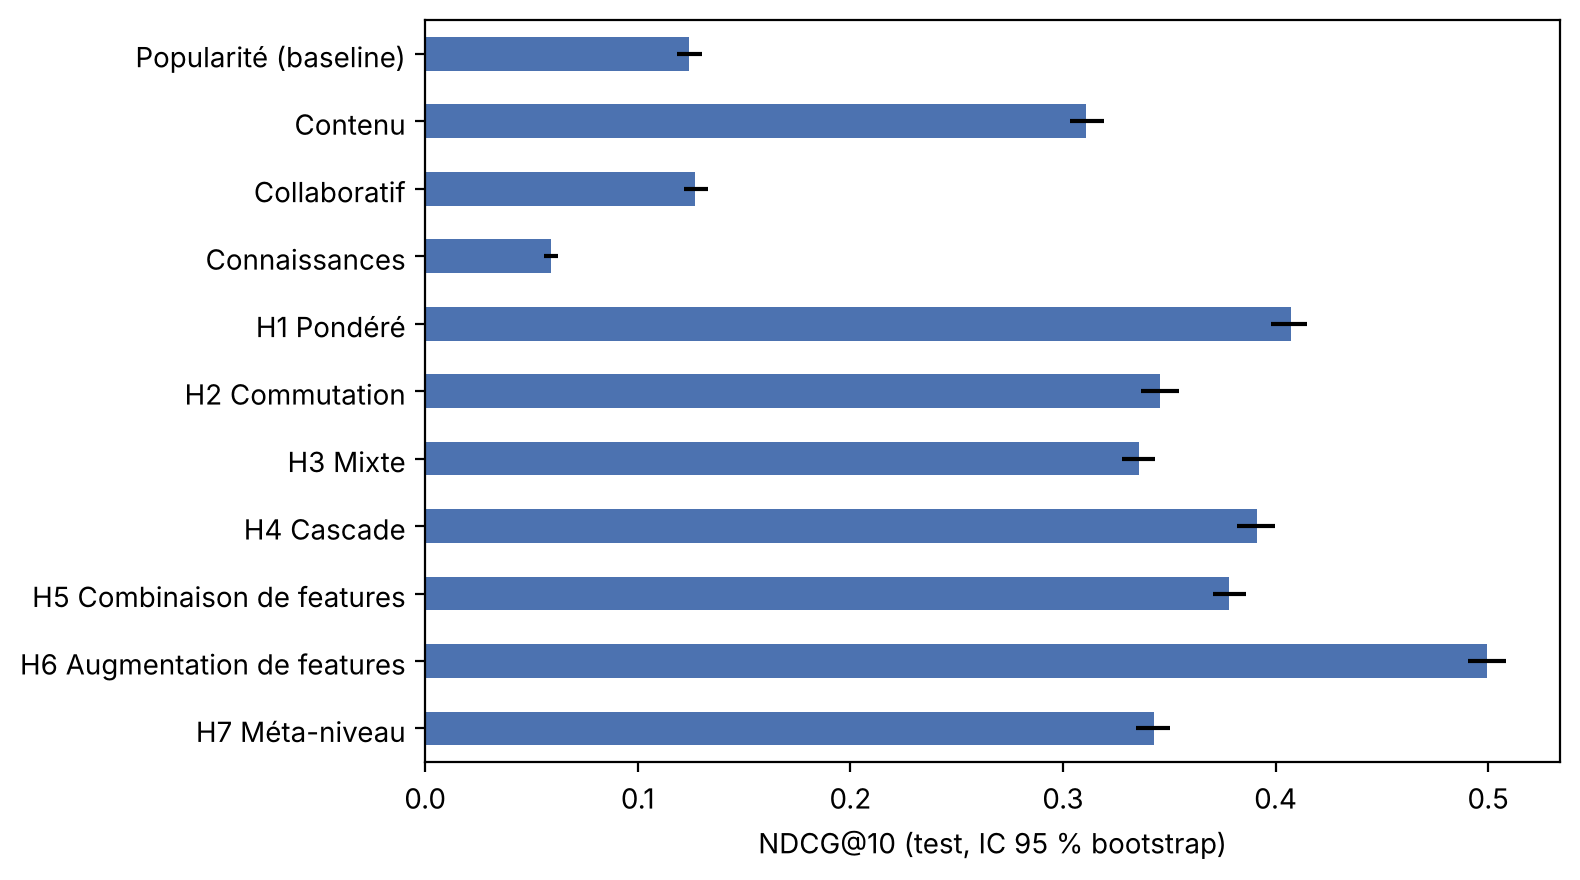

,NDCG@10,IC bas,IC haut
Popularité (baseline),0.1241,0.1185,0.1301
Contenu,0.3107,0.3033,0.3191
Collaboratif,0.1270,0.1216,0.1332
Connaissances,0.0591,0.0558,0.0623
H1 Pondéré,0.4071,0.3978,0.4149
H2 Commutation,0.3459,0.3367,0.3548
H3 Mixte,0.3359,0.3278,0.3434
H4 Cascade,0.3913,0.3820,0.3995
H5 Combinaison de features,0.3781,0.3705,0.3862
H6 Augmentation de features,0.4995,0.4905,0.5084


In [14]:
# Intervalles de confiance à 95 % (bootstrap sur les requêtes) pour NDCG@10
rng = np.random.default_rng(SEED)
nq = res.q.nunique(); boots = rng.integers(0, nq, size=(300, nq))
ci = {}
for m, g in res.groupby("method", sort=False):
    v = g.sort_values("q")[f"NDCG@{K}"].values
    b = v[boots].mean(axis=1); ci[m] = (v.mean(), *np.percentile(b, [2.5, 97.5]))
ci = pd.DataFrame(ci, index=["NDCG@10", "IC bas", "IC haut"]).T
ax = ci["NDCG@10"].plot.barh(xerr=[ci["NDCG@10"] - ci["IC bas"], ci["IC haut"] - ci["NDCG@10"]], figsize=(8, 4.5), color="#4C72B0")
ax.invert_yaxis(); ax.set_xlabel("NDCG@10 (test, IC 95 % bootstrap)"); plt.tight_layout(); plt.savefig(f"{FIG}/ndcg_test.png", dpi=150); plt.show()
ci

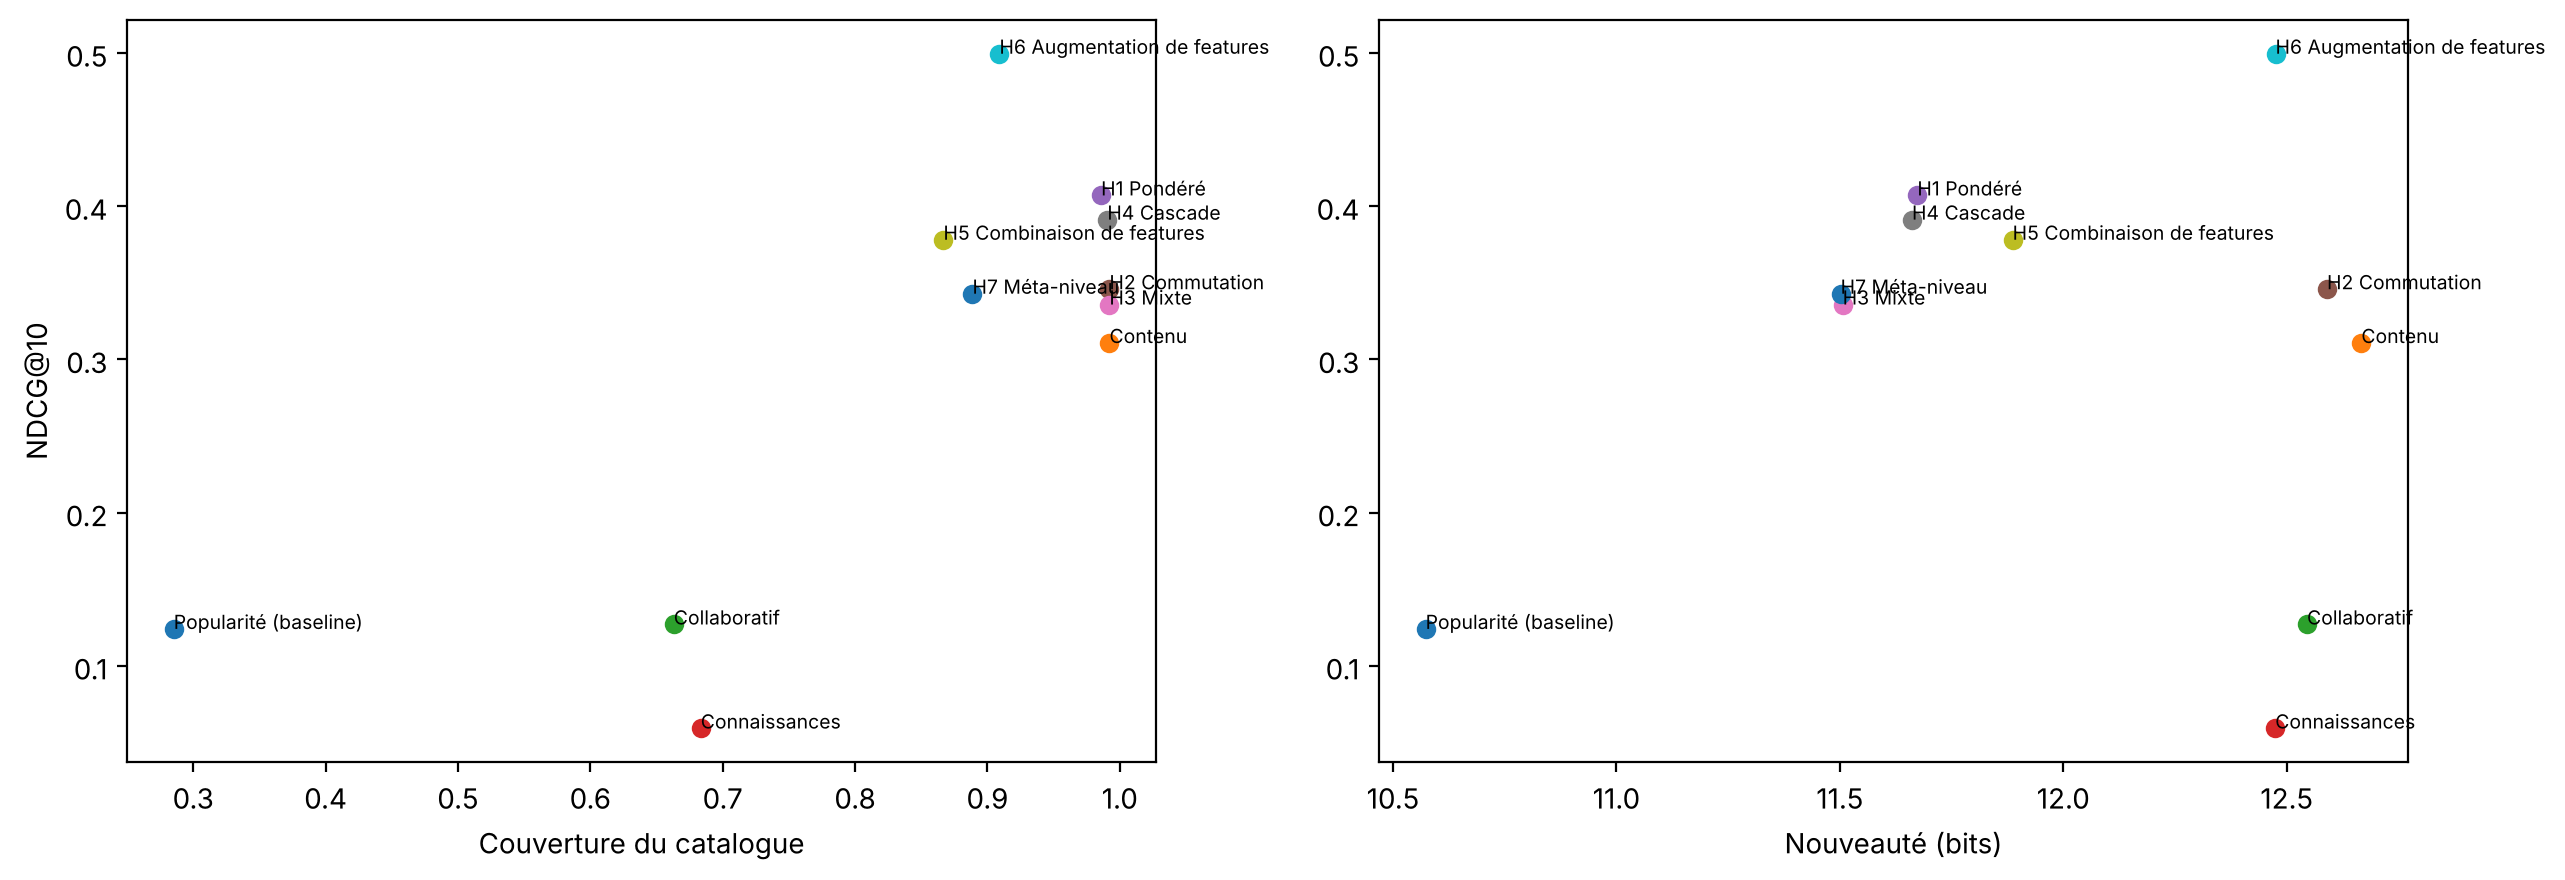

In [15]:
# Précision vs au-delà de la précision
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for m, r in summary.iterrows():
    ax[0].scatter(r["Couverture"], r[f"NDCG@{K}"]); ax[0].annotate(m, (r["Couverture"], r[f"NDCG@{K}"]), fontsize=7)
    ax[1].scatter(r["Nouveauté"], r[f"NDCG@{K}"]); ax[1].annotate(m, (r["Nouveauté"], r[f"NDCG@{K}"]), fontsize=7)
ax[0].set_xlabel("Couverture du catalogue"); ax[1].set_xlabel("Nouveauté (bits)"); ax[0].set_ylabel("NDCG@10")
plt.tight_layout(); plt.savefig(f"{FIG}/compromis.png", dpi=150); plt.show()

## 7. Cold-start

Trois analyses :
1. **Nouveaux candidats** (aucune interaction avant *t*) vs **candidats connus** — partition naturelle du test.
2. **Nouvelles offres** : HR@10 calculé uniquement sur les offres vraies qui n'avaient reçu aucune candidature avant *t*.
3. **Nouveaux candidats simulés** : on reprend les requêtes des candidats connus en **masquant leur historique** ;
   on mesure ce que chaque méthode perd quand le candidat devient « nouveau ».

In [16]:
cols = [f"P@{K}", f"R@{K}", f"NDCG@{K}", f"HR@{K}", "MRR", f"HR@{K} offres nouvelles", "n_requêtes"]
cold_tab = summarize(res, cached_test, ks=(5, K), group="cold")[cols]
warm_tab = summarize(res, cached_test, ks=(5, K), group="warm")[cols]
display(pd.concat({"Nouveaux candidats": cold_tab, "Candidats connus": warm_tab}, axis=1).round(4))

Nouveaux candidats                                                                   Candidats connus                          \
                                          P@10    R@10 NDCG@10   HR@10     MRR HR@10 offres nouvelles n_requêtes             P@10    R@10 NDCG@10   HR@10   
Popularité (baseline)                   0.0239  0.2382  0.1279  0.2385  0.1152                 0.0000     5438.0           0.0229  0.2279  0.1167  0.2289   
Contenu                                 0.0477  0.4766  0.2953  0.4768  0.2526                 0.5949     5438.0           0.0575  0.5715  0.3409  0.5738   
Collaboratif                            0.0070  0.0701  0.0297  0.0702  0.0331                 0.0854     5438.0           0.0402  0.4002  0.3175  0.4017   
Connaissances                           0.0128  0.1282  0.0619  0.1284  0.0629                 0.1582     5438.0           0.0124  0.1234  0.0538  0.1242   
H1 Pondéré                              0.0551  0.5512  0.3726  0.5513  0.3288                 0.5222     5438.0           0.0663  0.6592  0.4745  0.6616   
H2 Commutation                          0.0477  0.4766  0.2953  0.4768  0.2526                 0.5949     5438.0           0.0643  0.6388  0.4447  0.6407   
H3 Mixte                                0.0533  0.5326  0.3367  0.5329  0.2878                 0.4430     5438.0           0.0567  0.5641  0.3341  0.5666   
H4 Cascade                              0.0534  0.5337  0.3520  0.5338  0.3085                 0.4968     5438.0           0.0659  0.6549  0.4682  0.6573   
H5 Combinaison de features              0.0563  0.5622  0.3925  0.5623  0.3504                 0.4842     5438.0           0.0555  0.5526  0.3501  0.5544   
H6 Augmentation de features             0.0633  0.6323  0.4849  0.6324  0.4458                 0.6741     5438.0           0.0734  0.7307  0.5282  0.7325   
H7 Méta-niveau                          0.0504  0.5033  0.3497  0.5037  0.3113                 0.0190     5438.0           0.0554  0.5506  0.3297  0.5533   

                                                                       
                                MRR HR@10 offres nouvelles n_requêtes  
Popularité (baseline)        0.1058                 0.0000     2778.0  
Contenu                      0.2842                 0.6000     2778.0  
Collaboratif                 0.3015                 0.0667     2778.0  
Connaissances                0.0530                 0.1267     2778.0  
H1 Pondéré                   0.4265                 0.5000     2778.0  
H2 Commutation               0.3948                 0.5733     2778.0  
H3 Mixte                     0.2786                 0.4133     2778.0  
H4 Cascade                   0.4202                 0.4533     2778.0  
H5 Combinaison de features   0.3005                 0.4333     2778.0  
H6 Augmentation de features  0.4704                 0.7333     2778.0  
H7 Méta-niveau               0.2726                 0.0000     2778.0

In [17]:
warm_q = pd.DataFrame([(u, t, tr) for (u, t, p, tr, c) in cached_test if c["n_past"] > 0], columns=["u", "t", "true_items"])
if len(warm_q):
    cached_hidden = precompute(ctx, warm_q, pool_fn, hide_user_history=True)
    cached_warm = [c for c in cached_test if c[4]["n_past"] > 0]
    r_real = summarize(evaluate(cached_warm, METHODS, ctx, ks=(K,)), cached_warm, ks=(K,))[f"NDCG@{K}"]
    r_hide = summarize(evaluate(cached_hidden, METHODS, ctx, ks=(K,)), cached_hidden, ks=(K,))[f"NDCG@{K}"]
    sim = pd.DataFrame({"avec historique": r_real, "historique masqué": r_hide})
    sim["perte (%)"] = 100 * (sim["historique masqué"] - sim["avec historique"]) / sim["avec historique"].replace(0, np.nan)
    display(sim.round(4))
else:
    print("Aucun candidat connu dans le test.")

,avec historique,historique masqué,perte (%)
Popularité (baseline),0.1167,0.1167,0.0000
Contenu,0.3409,0.2467,-27.6330
Collaboratif,0.3175,0.0295,-90.6997
Connaissances,0.0538,0.0538,0.0000
H1 Pondéré,0.4745,0.3130,-34.0286
H2 Commutation,0.4447,0.2467,-44.5339
H3 Mixte,0.3341,0.2633,-21.2098
H4 Cascade,0.4682,0.2977,-36.4095
H5 Combinaison de features,0.3501,0.3501,0.0000
H6 Augmentation de features,0.5282,0.4325,-18.1063


## 8. Interprétabilité et explications

In [18]:
print("Poids du pondéré :", W_BEST, "| Commutation :", SW, "| Cascade τ :", TAU)
coef = pd.DataFrame({"combinaison (H5)": pd.Series(ltr_raw.coefficients()),
                     "augmentation (H6)": pd.Series(ltr_aug.coefficients())})
coef.sort_values("augmentation (H6)", key=abs, ascending=False)

Poids du pondéré : {'pop': 0.2, 'cb': 0.30000000000000004, 'cf': 0.2, 'kb': 0.30000000000000004} | Commutation : {'n_min': 1, 'warm': 'cf', 'cold': 'cb'} | Cascade τ : 0.3


,combinaison (H5),augmentation (H6)
age_offre,-1.426,-1.434
log_pop_recente,0.686,0.892
score_contenu,NaN,0.734
score_meta,NaN,0.682
c_contrat,0.825,0.631
log_pop_totale,0.336,-0.545
log_hist_candidat,-0.098,-0.448
score_kb,NaN,0.338
score_cf,NaN,0.303
cov_skills,0.428,0.255


In [19]:
# Exemple d'explication (format affiché dans la démo Streamlit)
u, t, p, true, c = next(x for x in cached_test if np.isin(x[3], x[2]).any())
s = METHODS["H6 Augmentation de features"](c, u, t, p)
order = np.argsort(-s)[:3]
for rank, idx in enumerate(order, 1):
    e = explain(ctx, c, p, idx, u, t)
    print(f"#{rank} offre {jobs.job_id[e['job']][:10]}… {'(VRAIE)' if e['job'] in true else ''}")
    for r in e["reasons"]: print("   +", r)
    for w in e["warnings"]: print("   −", w)

#1 offre 2794… (VRAIE)
   + Critères respectés : diplôme, expérience, séniorité, localisation, contrat, langues.
   + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
   + Offre active : 28 candidature(s) ces 30 derniers jours.
   − Compétences à acquérir : confluence, java, jira, sql.
#2 offre 2298… 
   + 1/4 compétences demandées présentes dans votre profil (agile methodologies).
   + Critères respectés : diplôme, expérience, séniorité, localisation, contrat, langues.
   + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
   + Offre active : 54 candidature(s) ces 30 derniers jours.
   − Compétences à acquérir : confluence, jira, scrum.
#3 offre 2309… 
   + 1/4 compétences demandées présentes dans votre profil (project management).
   + Critères respectés : diplôme, expérience, séniorité, localisation, contrat, langues.
   + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
   + Offre active : 32 candida

In [20]:
# Sauvegarde des modèles réglés pour la démo Streamlit (app.py)
import joblib
joblib.dump({"W_BEST": W_BEST, "SW": SW, "TAU": TAU, "second": second, "ltr_raw": ltr_raw, "ltr_aug": ltr_aug,
             "window": W, "train_end": train_end, "summary": summary}, "models.joblib")
print("models.joblib écrit")

models.joblib écrit


## Conclusion
Les tableaux ci-dessus sont repris et discutés dans le rapport. Points à retenir (voir rapport pour les chiffres) :
la dimension temporelle (offres actives, popularité récente) et le cold-start dominent ce dataset ; les hybrides qui
apprennent à combiner signaux de contenu, de contraintes et de popularité dépassent nettement chaque moteur seul.